# Task 1 – N-Queens: Propositional Logic (SAT) & Min-Conflicts

In [1]:
import sys, os
sys.path.insert(0, os.getcwd())
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from nqueens.models import Board
from nqueens.constraints import ConstraintDiscoverer, CNFConverter
from nqueens.sat_solver import SATQueensSolver
from nqueens.min_conflicts import MinConflictsSolver, MaxConflictMinConflictsSolver
from nqueens.benchmark import Benchmark

def draw(queens, title=""):
    n = len(queens)
    fig, ax = plt.subplots(figsize=(5, 5))
    for r in range(n):
        for c in range(n):
            ax.add_patch(Rectangle((c, n-1-r), 1, 1, color="#f0d9b5" if (r+c)%2==0 else "#b58863"))
    for c, r in enumerate(queens):
        ax.text(c+.5, n-1-r+.5, "♛", ha="center", va="center", fontsize=max(6, 200//n), color="#1b5e20")
    ax.set_xlim(0, n); ax.set_ylim(0, n); ax.set_aspect("equal"); ax.axis("off"); ax.set_title(title)
    plt.show()

## 1. Mô hình hóa: ràng buộc → CNF (ví dụ N = 4)

In [2]:
b = Board(4)
cons = ConstraintDiscoverer(b).discover()
clauses = CNFConverter(b).convert(cons)
print("Số ràng buộc:", len(cons), "| Số mệnh đề CNF:", len(clauses))
print("Ví dụ 5 mệnh đề đầu:", clauses[:5])

Số ràng buộc: 26 | Số mệnh đề CNF: 84
Ví dụ 5 mệnh đề đầu: [[1, 2, 3, 4], [-1, -2], [-1, -3], [-1, -4], [-2, -3]]


## 2. SAT với Glucose3

True 64 744 0.0012s
. . . Q . . . .
. Q . . . . . .
. . . . . . Q .
. . Q . . . . .
. . . . . Q . .
. . . . . . . Q
. . . . Q . . .
Q . . . . . . .


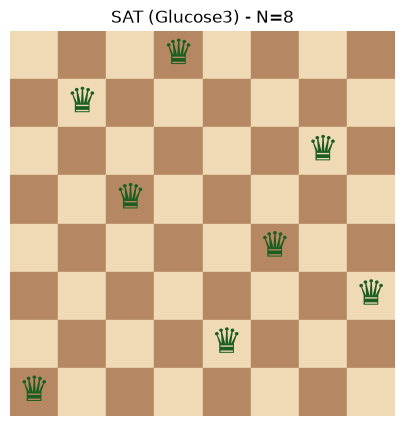

In [3]:
res = SATQueensSolver().solve(8)
print(res.solved, res.num_vars, res.num_clauses, f"{res.time_s:.4f}s")
if res.queens is not None:
    print(Board.to_text(res.queens))
    draw(res.queens, "SAT (Glucose3) - N=8")
else:
    print("Solver không tìm ra nghiệm!")

In [4]:
sizes = [4, 8, 12, 16, 20, 24, 32, 40, 48]
Benchmark().run_sat(sizes)

N  | #vars | #clauses | encode(s) | solve(s) | valid
---+-------+----------+-----------+----------+------
4  | 16    | 84       | 0.0001    | 0.0002   | True 
8  | 64    | 744      | 0.0006    | 0.0007   | True 
12 | 144   | 2620     | 0.0018    | 0.0021   | True 
16 | 256   | 6352     | 0.0029    | 0.0190   | True 
20 | 400   | 12580    | 0.0035    | 0.0076   | True 
24 | 576   | 21944    | 0.0061    | 0.0772   | True 
32 | 1024  | 52640    | 0.0504    | 0.0260   | True 
40 | 1600  | 103560   | 0.0667    | 0.0618   | True 
48 | 2304  | 179824   | 0.1290    | 0.0889   | True 


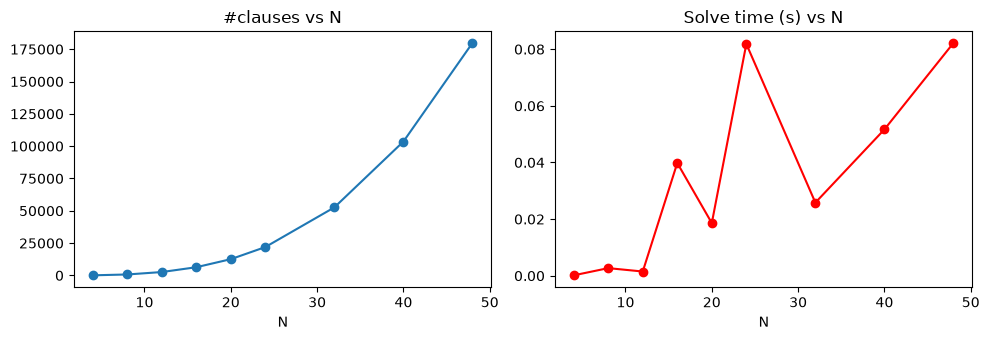

In [5]:
rs = [SATQueensSolver().solve(n) for n in sizes]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(sizes, [r.num_clauses for r in rs], "o-"); ax[0].set_title("#clauses vs N"); ax[0].set_xlabel("N")
ax[1].plot(sizes, [r.time_s for r in rs], "o-r"); ax[1].set_title("Solve time (s) vs N"); ax[1].set_xlabel("N")
plt.tight_layout(); plt.show()

## 3. Min-Conflicts: chuẩn vs heuristic MaxConflict

Min-Conflicts | solved: True | steps: 27 | 0.0004s


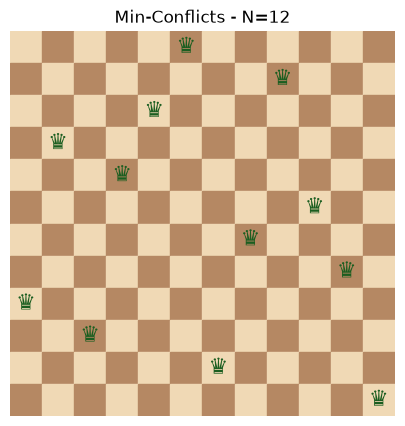

Min-Conflicts + MaxConflict | solved: True | steps: 44 | 0.0006s


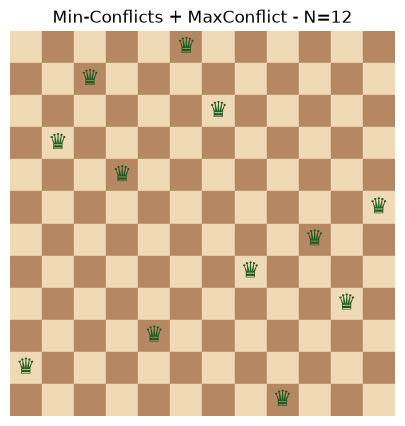

In [6]:
for S in (MinConflictsSolver, MaxConflictMinConflictsSolver):
    r = S(seed=1).solve(12)
    print(r.solver, "| solved:", r.solved, "| steps:", r.steps, f"| {r.time_s:.4f}s")
    if r.queens is not None:
        draw(r.queens, f"{r.solver} - N=12")
    else:
        print(f"{r.solver} không tìm ra nghiệm với N=12 (thử seed khác)")

In [7]:
Benchmark().run_min_conflicts([8, 16, 32, 64, 100, 200, 500], runs=10, seed=0)

N   | algorithm                   | success | avg steps | avg time(s)
----+-----------------------------+---------+-----------+------------
8   | Min-Conflicts               | 10/10   | 51.3      | 0.0006     
8   | Min-Conflicts + MaxConflict | 9/10    | 30.9      | 0.0004     
16  | Min-Conflicts               | 10/10   | 79.9      | 0.0009     
16  | Min-Conflicts + MaxConflict | 10/10   | 38.3      | 0.0006     
32  | Min-Conflicts               | 10/10   | 76.7      | 0.0014     
32  | Min-Conflicts + MaxConflict | 10/10   | 62.4      | 0.0016     
64  | Min-Conflicts               | 10/10   | 127.7     | 0.0060     
64  | Min-Conflicts + MaxConflict | 10/10   | 83.1      | 0.0038     
100 | Min-Conflicts               | 10/10   | 124.4     | 0.0066     
100 | Min-Conflicts + MaxConflict | 10/10   | 116.1     | 0.0070     
200 | Min-Conflicts               | 10/10   | 208.0     | 0.0190     
200 | Min-Conflicts + MaxConflict | 10/10   | 174.4     | 0.0197     
500 | Min-Conflicts 